# WRF Urban Parameters Analysis by LU_INDEX

Compare four urban parameters (FRC_URB2D, BUILD_AREA_FRACTION, BUILD_SURF_RATIO, BUILD_HEIGHT) across LU_INDEX categories (51-60) for three WRF experiments (LCZ, WSF-MB, Geoscape) within a lat/lon box over Sydney.

**Output**: 
- Grouped boxplot figure showing the three experiments
- CSV file with grid counts per LU_INDEX category

## 1. Import Libraries

In [10]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Dict, Tuple, List
import warnings
warnings.filterwarnings('ignore')
import string

## 2. Define File Paths, Experiment Labels, and Outputs

In [2]:
# Define base path (notebook working directory)
base_path = Path.cwd()
print(f"Working directory: {base_path}")

# Experiment file paths
file_paths = {
    'LCZ': base_path / 'LCZ' / 'wrfinput_d02',
    'WSF-MB': base_path / 'WSF-MB' / 'wrfinput_d02',
    'Geoscape': base_path / 'Geoscape' / 'wrfinput_d02'
}

# Experiment labels (order: LCZ=blue, WSF-MB=green, Geoscape=red)
experiment_labels = ['LCZ', 'WSF-MB', 'Geoscape']
experiment_colors = {'LCZ': 'blue', 'WSF-MB': 'green', 'Geoscape': 'red'}

# Output filenames
output_csv = base_path / 'lu_counts.csv'
output_figure = base_path / 'urban_boxplots.png'

# Verify file paths exist
for exp, fpath in file_paths.items():
    if fpath.exists():
        print(f"✓ {exp}: {fpath}")
    else:
        print(f"✗ {exp}: {fpath} NOT FOUND")

Working directory: c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026
✓ LCZ: c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\LCZ\wrfinput_d02
✓ WSF-MB: c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\WSF-MB\wrfinput_d02
✓ Geoscape: c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\Geoscape\wrfinput_d02


## 3. Open WRF Input Files

In [3]:
# Load WRF input files using xarray
datasets = {}
for exp in experiment_labels:
    try:
        ds = xr.open_dataset(str(file_paths[exp]), decode_cf=False)
        datasets[exp] = ds
        print(f"✓ Loaded {exp}: {ds.dims}")
    except Exception as e:
        print(f"✗ Failed to load {exp}: {e}")

# Quick inspection of first dataset
if datasets:
    first_exp = experiment_labels[0]
    print(f"\nFirst dataset ({first_exp}) variables:")
    print(list(datasets[first_exp].data_vars))

✓ Loaded LCZ: FrozenMappingWarningOnValuesAccess({'Time': 1, 'south_north': 290, 'west_east': 280})
✓ Loaded WSF-MB: FrozenMappingWarningOnValuesAccess({'Time': 1, 'south_north': 290, 'west_east': 280})
✓ Loaded Geoscape: FrozenMappingWarningOnValuesAccess({'Time': 1, 'south_north': 290, 'west_east': 280})

First dataset (LCZ) variables:
['BUILD_AREA_FRACTION', 'BUILD_HEIGHT', 'BUILD_SURF_RATIO', 'FRC_URB2D', 'LU_INDEX', 'XLAT', 'XLONG']


## 4. Define Lat/Lon Bounds and Subset Function

In [4]:
# Define lat/lon bounds (Sydney region)
lat_min, lat_max = -34.14, -33.55
lon_min, lon_max = 150.57, 151.37

print(f"Spatial bounds: lat [{lat_min}, {lat_max}], lon [{lon_min}, {lon_max}]")

def subset_by_bounds(ds: xr.Dataset, lat_min: float, lat_max: float, 
                     lon_min: float, lon_max: float) -> np.ndarray:
    """
    Create boolean mask for grid points within lat/lon bounds.
    
    Parameters
    ----------
    ds : xr.Dataset
        WRF dataset with XLAT and XLONG variables
    lat_min, lat_max, lon_min, lon_max : float
        Bounding box in degrees
        
    Returns
    -------
    mask : np.ndarray (bool)
        Boolean mask of same shape as XLAT/XLONG where True indicates point is within bounds
    """
    xlat = ds['XLAT'].values
    xlong = ds['XLONG'].values
    
    mask = ((xlat >= lat_min) & (xlat <= lat_max) & 
            (xlong >= lon_min) & (xlong <= lon_max))
    
    return mask

# Test subset function on first dataset
if datasets:
    first_exp = experiment_labels[0]
    test_mask = subset_by_bounds(datasets[first_exp], lat_min, lat_max, lon_min, lon_max)
    print(f"\nSubset mask for {first_exp}: {test_mask.sum()} grid points within bounds")

Spatial bounds: lat [-34.14, -33.55], lon [150.57, 151.37]

Subset mask for LCZ: 4861 grid points within bounds


## 5. Mask by LU_INDEX and Extract Parameter Arrays

In [5]:
# Urban parameters to extract
urban_params = ['FRC_URB2D', 'BUILD_AREA_FRACTION', 'BUILD_SURF_RATIO', 'BUILD_HEIGHT']
param_units = {
    'FRC_URB2D': 'dimensionless',
    'BUILD_AREA_FRACTION': 'dimensionless',
    'BUILD_SURF_RATIO': 'dimensionless',
    'BUILD_HEIGHT': 'm'
}
param_names = {
    'FRC_URB2D': 'Impervious Fraction',
    'BUILD_AREA_FRACTION': 'Plan Area Density',
    'BUILD_SURF_RATIO': 'Building Surface to\nPlan Area Ratio',
    'BUILD_HEIGHT': 'Area-Weighted\nMean Building Height (m)'
}

# LU_INDEX categories: 51 to 60 (10 categories)
lu_indices = list(range(51, 61))
lcz_labels = [f'LCZ {i+1}' for i in range(10)]  # LCZ 1 to LCZ 10

# Extract data for each parameter, experiment, and LU_INDEX
# Structure: data[param][experiment][LU_INDEX] = 1D array of values
data = {}

for param in urban_params:
    data[param] = {}
    for exp in experiment_labels:
        data[param][exp] = {}
        
        if exp not in datasets:
            print(f"Warning: Dataset {exp} not loaded, skipping")
            continue
            
        ds = datasets[exp]
        
        # Get subset mask (lat/lon bounds)
        subset_mask = subset_by_bounds(ds, lat_min, lat_max, lon_min, lon_max)
        
        # Get LU_INDEX array
        lu_index = ds['LU_INDEX'].values
        
        # Build valid mask: subset AND LU_INDEX > 50 AND LU_INDEX <= 60
        valid_mask = subset_mask & (lu_index > 50) & (lu_index <= 60)
        
        # Extract parameter values
        param_values = ds[param].values
        
        # For each LU_INDEX, extract the parameter values where that LU is present and valid
        for lu in lu_indices:
            # Mask where LU_INDEX equals this value AND other conditions are met
            lu_mask = valid_mask & (lu_index == lu)
            
            # Get parameter values at these locations
            values = param_values[lu_mask].flatten()
            
            # Remove NaN values
            values = values[~np.isnan(values)]
            
            # Store as 1D array
            data[param][exp][lu] = values
        
        print(f"✓ Extracted {param} for {exp}")

print("\nData extraction complete")

✓ Extracted FRC_URB2D for LCZ
✓ Extracted FRC_URB2D for WSF-MB
✓ Extracted FRC_URB2D for Geoscape
✓ Extracted BUILD_AREA_FRACTION for LCZ
✓ Extracted BUILD_AREA_FRACTION for WSF-MB
✓ Extracted BUILD_AREA_FRACTION for Geoscape
✓ Extracted BUILD_SURF_RATIO for LCZ
✓ Extracted BUILD_SURF_RATIO for WSF-MB
✓ Extracted BUILD_SURF_RATIO for Geoscape
✓ Extracted BUILD_HEIGHT for LCZ
✓ Extracted BUILD_HEIGHT for WSF-MB
✓ Extracted BUILD_HEIGHT for Geoscape

Data extraction complete


## 6. Compute Per-LU_INDEX Grid Counts and Save CSV

In [6]:
# Compute grid counts for each LU_INDEX and experiment
# Use the first parameter as reference (all should have same grids)
reference_param = urban_params[0]

counts_data = []

for exp in experiment_labels:
    for lu in lu_indices:
        # Get count of grid points for this LU_INDEX and experiment
        if exp in data[reference_param] and lu in data[reference_param][exp]:
            count = len(data[reference_param][exp][lu])
        else:
            count = 0
        
        lcz_label = lcz_labels[lu - 51]  # LU 51 -> LCZ 1, LU 52 -> LCZ 2, etc.
        counts_data.append({
            'experiment': exp,
            'LU_INDEX': lu,
            'LCZ_Label': lcz_label,
            'count': count
        })

# Create DataFrame and save to CSV
df_counts = pd.DataFrame(counts_data)
df_counts.to_csv(str(output_csv), index=False)

print(f"✓ Saved grid counts to {output_csv}")
print("\nGrid counts per LU_INDEX:")
print(df_counts.pivot_table(values='count', index='LU_INDEX', columns='experiment', aggfunc='first'))

# Identify which LU_INDEX has zero count
zero_count_lus = df_counts[df_counts['count'] == 0]['LU_INDEX'].unique()
if len(zero_count_lus) > 0:
    print(f"\n⚠ LU_INDEX with zero grids: {zero_count_lus.tolist()}")

✓ Saved grid counts to c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\lu_counts.csv

Grid counts per LU_INDEX:
experiment  Geoscape  LCZ  WSF-MB
LU_INDEX                         
51                 5    5       5
52                 0    0       0
53               618  618     618
54                 1    1       1
55                11   11      11
56               686  686     686
57                 0    0       0
58               191  191     191
59               106  106     106
60                11   11      11

⚠ LU_INDEX with zero grids: [52, 57]


## 7. Prepare Grouped Boxplot Data Structure

In [7]:
# Prepare boxplot data and positions
# We want groups of 3 boxes (one per experiment) with no gap between them,
# and gaps between groups

# Box width (doubled for better visibility)
box_width = 0.5

# Position strategy:
# - 10 LU_INDEX groups (LCZ 1 to 10)
# - 3 boxes per group (LCZ, WSF-MB, Geoscape)
# - spacing: base position for group i = i * 4
#   then offsets for the 3 boxes: 0, 1, 2 (so they are at i*4+0, i*4+1, i*4+2)
#   this creates touching boxes within a group, and gaps between groups

base_positions = np.arange(10) * 4  # 0, 4, 8, 12, ..., 36
offsets_per_exp = {exp: offset for offset, exp in enumerate(experiment_labels)}  # 0, 1, 2

# Build boxplot data structure for each parameter
boxplot_data = {}  # boxplot_data[param] = list of (data_lists, positions, colors_per_box)

for param in urban_params:
    all_data_lists = []
    all_positions = []
    all_colors = []
    
    for lu_idx, lu in enumerate(lu_indices):
        # For each LU_INDEX, add data for each experiment in order
        base_pos = base_positions[lu_idx]
        
        for exp in experiment_labels:
            # Get the data for this LU and experiment
            if exp in data[param] and lu in data[param][exp]:
                values = data[param][exp][lu]
            else:
                values = np.array([])
            
            # Only add to plot if we have data OR to maintain position structure
            # We'll add empty arrays for missing data (matplotlib handles this)
            all_data_lists.append(values)
            
            # Position for this box: base + offset
            pos = base_pos + offsets_per_exp[exp]
            all_positions.append(pos)
            
            # Color for this experiment
            all_colors.append(experiment_colors[exp])
    
    boxplot_data[param] = {
        'data': all_data_lists,
        'positions': all_positions,
        'colors': all_colors,
        'base_positions': base_positions,
        'lcz_labels': lcz_labels
    }

print(f"Prepared boxplot data for {len(boxplot_data)} parameters")
print(f"Total boxes per parameter: {len(all_data_lists)}")

Prepared boxplot data for 4 parameters
Total boxes per parameter: 30


## 8. Plot 4 Horizontal Subplots with Grouped Boxplots

✓ Saved figure to c:\Users\z5493395\OneDrive - UNSW\Documents\PhD\Projects\Project 1\paper\Urban Climate submission\WRF_Files-Fazeli_et_al_2026\urban_boxplots.png


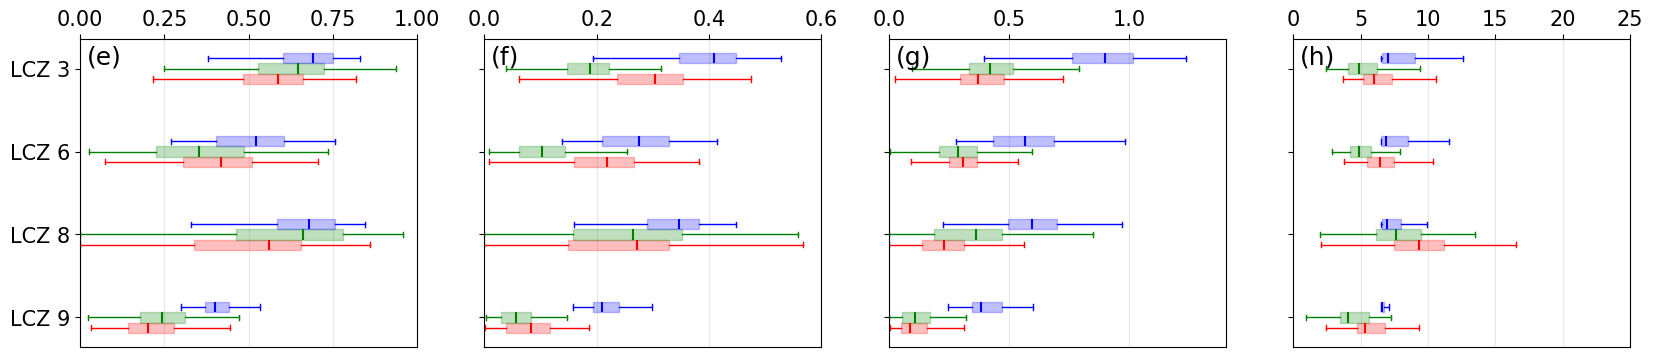

In [14]:
# Create figure with 4 subplots (4 columns, 1 row)
#fig, axes = plt.subplots(1, 4, figsize=(17, 3.3), sharey=True, gridspec_kw={'wspace': 0.2})
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True,  gridspec_kw={'wspace': 0.2}) #

# Define colors for experiments
colors_list = [experiment_colors[exp] for exp in experiment_labels]

# Keep only selected LCZ categories in the plot
selected_lu = [53, 56, 58, 59]  # LCZ 3, LCZ 6, LCZ 8, LCZ 9
selected_group_idx = [lu - 51 for lu in selected_lu]
selected_labels = [f'LCZ {lu - 50}' for lu in selected_lu]

# Desired plotting order for experiments (bottom-to-top in the grouped boxes):
plot_order = ['Geoscape', 'WSF-MB', 'LCZ']  # red, green, blue

# Value ranges requested for each urban parameter
x_ranges = {
    'FRC_URB2D': (0, 1),
    'BUILD_AREA_FRACTION': (0, 0.6),
    'BUILD_SURF_RATIO': (0, 1.4),
    'BUILD_HEIGHT': (0, 25),
}

# Plot each parameter in its own subplot
for ax_idx, param in enumerate(urban_params):
    ax = axes[ax_idx]
    
    # Get boxplot data for this parameter
    bp_data = boxplot_data[param]

    # Filter data to selected LCZ groups only, but in the requested experiment order
    n_exp = len(experiment_labels)
    keep_idx = []
    for g in selected_group_idx:
        for exp_name in plot_order:
            e_idx = experiment_labels.index(exp_name)
            keep_idx.append(g * n_exp + e_idx)

    filtered_data = [bp_data['data'][i] for i in keep_idx]
    filtered_colors = [bp_data['colors'][i] for i in keep_idx]

    # Horizontal grouped boxplots: LCZ groups on the y-axis, values on the x-axis
    plot_box_width = box_width / 4
    intra_offsets = np.array([0.0, plot_box_width, 2 * plot_box_width])
    group_stride = 1.0
    # Reverse the order of group bases so LCZ3 is topmost and LCZ9 bottommost
    compact_group_bases = (np.arange(len(selected_lu))[::-1]) * group_stride

    filtered_positions = []
    for base in compact_group_bases:
        filtered_positions.extend((base + intra_offsets).tolist())

    bp = ax.boxplot(
        filtered_data,
        positions=filtered_positions,
        widths=plot_box_width,
        vert=False,
        patch_artist=True,
        showfliers=False,
        manage_ticks=False
    )
    
    # Color the boxes according to experiment and set transparent fill
    for i, patch in enumerate(bp['boxes']):
        color = filtered_colors[i]
        patch.set_facecolor(color)
        patch.set_alpha(0.25)
        patch.set_edgecolor(color)
        patch.set_linewidth(1.0)

    # Color medians, whiskers and caps by experiment color
    n_boxes = len(bp.get('boxes', []))
    for i in range(n_boxes):
        color = filtered_colors[i]
        # median
        if 'medians' in bp and len(bp['medians']) > i:
            med = bp['medians'][i]
            med.set_color(color)
            med.set_linewidth(1.5)
        # whiskers (2 per box)
        if 'whiskers' in bp and len(bp['whiskers']) >= 2 * (i + 1):
            w1 = bp['whiskers'][2 * i]
            w2 = bp['whiskers'][2 * i + 1]
            w1.set_color(color)
            w1.set_linewidth(1.0)
            w2.set_color(color)
            w2.set_linewidth(1.0)
        # caps (2 per box)
        if 'caps' in bp and len(bp['caps']) >= 2 * (i + 1):
            c1 = bp['caps'][2 * i]
            c2 = bp['caps'][2 * i + 1]
            c1.set_color(color)
            c1.set_linewidth(1.0)
            c2.set_color(color)
            c2.set_linewidth(1.0)

    # Set y-axis: group labels at center of each group
    ytick_positions = compact_group_bases + intra_offsets.mean()
    ax.set_yticks(ytick_positions)
    if ax_idx == 0:
        ax.set_yticklabels(selected_labels, rotation=0) #labelsize=10, 
    else:
        ax.tick_params(axis='y', labelleft=False)
    ax.invert_yaxis()

    # Fix the requested x-range for each parameter
    ax.set_xlim(*x_ranges[param])
    ax.tick_params(axis='both', labelsize=15)

    # Move x ticks and labels to the top
    ax.xaxis.set_ticks_position('top')
    ax.xaxis.set_label_position('top')
    ax.tick_params(axis='x', top=True, labeltop=True, bottom=False, labelbottom=False)

    # For impervious fraction, set explicit ticks at 0,0.25,0.5,0.75,1.0
    if param == 'FRC_URB2D':
        frc_ticks = [0.0, 0.25, 0.5, 0.75, 1.0]
        ax.set_xticks(frc_ticks)
        ax.set_xticklabels([f"{t:.2f}" for t in frc_ticks], fontsize=15)

    # Remove subplot titles
    ax.set_title('')

    ax.grid(True, alpha=0.3, axis='x')
    # Subplot label (a)-(d)
    ax.text(0.02, 0.98, f"({string.ascii_lowercase[4+ax_idx]})",
                    transform=ax.transAxes, fontsize=18, #fontweight="bold",
                    va="top", ha="left", zorder=10,
                    bbox=dict(facecolor="none", edgecolor="none", alpha=0.8, pad=2))

# Adjust layout
plt.tight_layout()

# Save figure
plt.savefig(str(output_figure), dpi=300, bbox_inches='tight')
print(f"✓ Saved figure to {output_figure}")

plt.show()